<a href="https://colab.research.google.com/github/ManalZar/COURSE/blob/main/CICS_302_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modelling Language/Information Transmission**

For our computer scinece 3 project we'll be building an agent based model to investigate the dynamics of language minorities.
This model is a simulation of the dynamics of communication within a community where a minority and a majority group coexist.


In this simulation, we will agent-based framework in python provided by the Mesa framework (https://mesa.readthedocs.io/en/master/).

We modify the model to use randomly generated network instead of the standard square grid here.


## **Imports**

In [9]:
!pip install mesa

In [17]:
!pip install stratum

ERROR: Could not find a version that satisfies the requirement stratum (from versions: 0.2.10, 0.2.11, 0.2.12, 0.2.15)
ERROR: No matching distribution found for stratum


In [8]:
import random
import pandas as pd
import seaborn as sns; sns.set()
import matplotlib.pyplot as plt
from IPython.display import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf')
from mesa import Agent, Model
from mesa.datacollection import DataCollector
from mesa.space import NetworkGrid
from mesa.time import RandomActivation
import numpy as np
import networkx as nx
import random

In [27]:
import pandas as pd
import numpy as np
from random import seed
from random import random
import editdistance
import copy
import seaborn as sns; sns.set()
import matplotlib.pyplot as plt
from IPython.display import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf')

## **Difference Measurement**

This is our metric to check whether the model leads to homogenized state of traits or remain  relatively diverse.

$difference = \frac{1}{n} \sum_{(i,j)\in Edges}|feature_i - feature_j|$


In [18]:
def f_difference(model):
    diff = 0
    conn = nx.edges(model.graph)
    for edge in conn:
        diff += np.mean(abs(model.schedule.agents[edge[0]].feature - model.schedule.agents[edge[1]].feature))
    return diff

## **Defining the Agent and the Model**

We will define the agent and the object model according to Mesa's framework. In this implementation, the action is done under the model's step instead of agent's step because it is simpler to just call one agent at a time using this interaction because the usual Mesa scheduler require every agent to be activated in each time step.

In [19]:
class axl_agent(Agent):
    '''Individual agent represented by a node in a network'''
    
    ## Initializing the agent.
    def __init__(self, unique_id, feat, trt, model):
        super().__init__(unique_id, model)
        self.feature = np.random.randint(low = 0, high = trt, size = feat)
    
    ## No content on agent's step.
    def step(self):
        return
    
class axl_model(Model):
    '''Model containing N agents connected in a network. Also change the value of agent here'''
    
    ##Initializing the model.
    def __init__(self, N, Graph, feat, trt):
        self.graph = Graph
        self.no_features = feat
        self.no_agents = N
        self.G = NetworkGrid(Graph)
        self.schedule = RandomActivation(self)
        
        ## Creating the agents.
        for i in range(self.no_agents):
            a = axl_agent(i, feat, trt, self)
            self.schedule.add(a)
        
        ## Creating collector for difference function defined above.
        self.datacollector = DataCollector(model_reporters = {"Propagation" : f_difference})
    
    ## At each model step, they collect data by using the collector.
    def step(self):
        self.datacollector.collect(self)
        agent = random.choice(self.schedule.agents)
        neigh = self.schedule.agents[random.choice(self.G.get_neighbors(agent.unique_id))]
        prob = np.count_nonzero(agent.feature - neigh.feature)/self.no_features
        if np.random.rand() < prob:
            index = np.random.choice(np.nonzero(agent.feature - neigh.feature)[0])
            agent.feature[index] = neigh.feature[index]

##**Running the model**

Below are the values required to initialize the model. We use networkx to generate random network.

Feel free to experiment with the parameters.

In [20]:
features = 8
traits = 5
N = 50
P = 0.1
time = 1000
graph = nx.fast_gnp_random_graph(N, P)

Creating the model.

In [21]:
model = axl_model(N, graph, features, traits)

Running the model for give time $T$.

In [22]:
for i in range(time):
    model.step()

## **Plotting the Difference over Time**

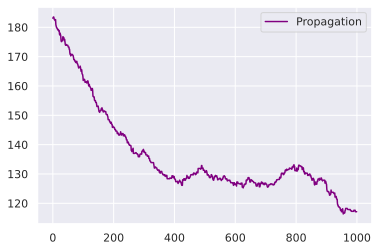

In [23]:
data = model.datacollector.get_model_vars_dataframe()
data.plot(color='purple')

In [24]:
agent = ['A', 0.5]
N = 100

In [25]:
agents = []

for i in range(N):
  language_skills = (0.2, 0.4, 0.6)
  p = (0.3, 0.4, 0.3)
  e = np.random.choice(language_skills, size=1, p=p)
  agents.append(['A', e[0]])
#e is the language skills: low e means you don't master the language 

In [26]:
df = pd.DataFrame(agents)

data = [[1, df[0].value_counts()['A']/N]]
output = pd.DataFrame(data, columns = ['tmax', 'p'])
output

,tmax,p
0,1,1.0


## **Networks and Randomness**

In [28]:
def textSpread(N):
  agents = []
  for i in range(N):
    language_skills = (0.2, 0.4, 0.6)
    p = (0.3, 0.4, 0.3)
    e = np.random.choice(language_skills, size=1, p=p)
    agents.append(['A', e[0]])
    #e is the language skills: low e means you don't master the language 

  df = pd.DataFrame(agents)

  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Choose a random agent to give him the text (tongue twister)
  i = np.random.choice(range(N))
  agents[i][0] = 'can you can a can as a canner can can a can!'

  #Simulation
  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))

    if j != k:
      if agents[j][0] != agents[k][0]:
        if agents[j][0] == 'can you can a can as a canner can can a can!':
          if random() >= agents[k][1]:
            agents[k][0] = 'can you can a can as a canner can can a can!'
        elif agents[k][0] == 'can you can a can as a canner can can a can!':
          if random() >= agents[j][1]:
            agents[j][0] = 'can you can a can as a canner can can a can!'
    df = pd.DataFrame(agents)
    exists = 'A' in df[0].unique()
    if exists:
      s = df[0].value_counts()['A']
    else:
      s = 0
    o = {'tmax': t, 'p': s/N}
    output = output.append(o, ignore_index = True)
  return output;

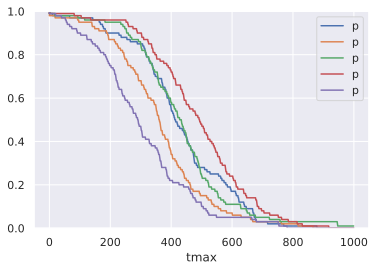

In [29]:
for r in range(5):
  output = textSpread(N)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

## **Networks**

In [30]:
def textSpread_1(N, F = 1):
  """
  agents is an empty list
  
  """
  agents = []
  seed(1)
  for i in range(N):
    e = random()
    population = (1, 2, 3)
    p = (0.3, 0.4, 0.3)
    net = np.random.choice(population, size=1, p=p)
    agents.append(['A', e, net[0]])
  #e is the language skills: low e means you don't master the language 

  #Choose a random agent to give him fake news
  if F < N:
    for i in range(F):
      f = np.random.choice(range(N))
      agents[f][0] = 'can you can a can as a canner can can a can!'
  else:
    print("Number of initial agents with the correct text should be inferior to the total population")
    return None;

  df = pd.DataFrame(agents)
  data = [[1, df[0].value_counts()['A']/N]]
  output = pd.DataFrame(data, columns = ['tmax', 'p'])
  #output

  #Simulation
  for t in range(1000):
    j = np.random.choice(range(N))
    k = np.random.choice(range(N))
    if j != k:
      #check if one of them has the FN
      if agents[j][0] != agents[k][0]:
        #check if they are from the same population 
        if agents[j][2] == agents[k][2]:
          if agents[j][0] == 'can you can a can as a canner can can a can!':
            if agents[j][1] >= agents[k][1]:
              agents[k][0] = 'can you can a can as a canner can can a can!'
          elif agents[k][0] == 'can you can a can as a canner can can a can!':
            if agents[k][1] >= agents[j][1]:
              agents[j][0] = 'can you can a can as a canner can can a can!'
        else:
          #case when they are not from the same population
          if agents[j][1] >= agents[k][1]:
            agents[k][0] = agents[j][0]
          else:
            agents[j][0] = agents[k][0]      
    df = pd.DataFrame(agents)
    exists = 'A' in df[0].unique()
    if exists:
      s = df[0].value_counts()['A']
    else:
      s = 0
    o = {'tmax': t, 'p': s/N}
    output = output.append(o, ignore_index = True)
  return output;

(0.0, 1.0)

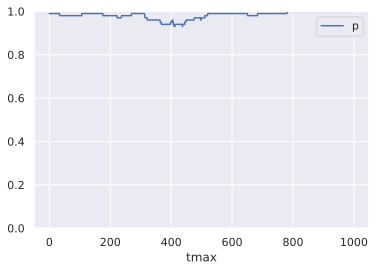

In [31]:
output = textSpread_1(N, 1)
ax = plt.gca()

output.plot(kind='line',x='tmax',y='p',ax=ax)
plt.ylim(0, 1)

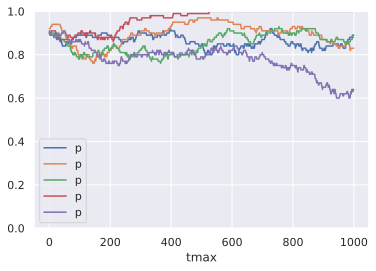

In [32]:
for r in range(5):
  output = textSpread_1(N, 10)
  ax = plt.gca()

  output.plot(kind='line',x='tmax',y='p',ax=ax)
  plt.ylim(0, 1)

## **Speech Transmission: Using Tongue Twisters and Signal Processing (Transformer de Fourier)**

In [48]:
import os
import librosa
import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import wavfile
import warnings

warnings.filterwarnings("ignore")

In [49]:
os.listdir('/content')

['.config', '.ipynb_checkpoints', 'audio', 'sample_data']

**Data Exploration and Visualization**

Data Exploration and Visualization helps us to understand the data as well as pre-processing steps in a better way.

**Visualization of Audio signal in time series domain**

Now, we’ll visualize the audio signal in the time series domain:

In [50]:
import numpy as np
from scipy.signal import argrelextrema
import matplotlib.pyplot as plt

In [51]:
train_audio_path = '/content/audio/'
samples, sample_rate = librosa.load(train_audio_path+'/WhatsApp-Ptt-2022-01-26-at-1.07.43-AM.wav', sr = 16000)

maxima = argrelextrema(samples, np.greater) 
minima = argrelextrema(samples, np.less)

In [52]:
print(maxima)

(array([    2,     6,     8, ..., 66763, 66768, 66771]),)


In [53]:
print(minima)

(array([    1,     4,     7, ..., 66765, 66769, 66772]),)


In [54]:
plt.plot(samples)
plt.plot(maxima[0], samples[maxima[0]], "x", ms=10)
plt.plot(minima[0], samples[minima[0]], ".", ms=10)
plt.xlabel('time')
plt.ylabel('Amplitude')
plt.show()

In [55]:
# train_audio_path = '/content/audio/'
# samples, sample_rate = librosa.load(train_audio_path+'/WhatsApp-Ptt-2022-01-26-at-1.07.43-AM.wav', sr = 16000)

# maxima = argrelextrema(samples, np.greater) 
# minima = argrelextrema(samples, np.less)

# fig = plt.figure(figsize=(14, 8))
# ax1 = fig.add_subplot(211)
# ax1.set_title('Raw wave of ' + '/content/audio/WhatsApp-Ptt-2022-01-26-at-1.07.43-AM.wav')
# ax1.set_xlabel('time')
# ax1.set_ylabel('Amplitude')
# ax1.plot(np.linspace(0, sample_rate/len(samples), sample_rate), samples)

**Sampling rate**

Let us now look at the sampling rate of the audio signals

In [56]:
ipd.Audio(samples, rate=sample_rate)

In [57]:
print(sample_rate)

16000


**Resampling**

From the above, we can understand that the sampling rate of the signal is 16000 hz. Let us resample it to 8000 hz since most of the speech related frequencies are present in 8000z

In [58]:
samples = librosa.resample(samples, sample_rate, 8000)
ipd.Audio(samples, rate=8000)

Now, let’s understand the number of recordings for each voice command:

In [59]:
labels=os.listdir(train_audio_path)
print(labels)

['WhatsApp-Ptt-2022-01-26-at-1.07.43-AM.wav', 'WhatsApp-Ptt-2022-01-18-at-11.11.12-PM.wav']


In [60]:
import os
for label in labels:
    path = train_audio_path + label

  # Get the path of current working directory
    print(path)

#dir_list = os.listdir(path)
#print(dir_list)

/content/audio/WhatsApp-Ptt-2022-01-26-at-1.07.43-AM.wav
/content/audio/WhatsApp-Ptt-2022-01-18-at-11.11.12-PM.wav


In [79]:
from networkx.algorithms.components.connected import node_connected_component
#find count of each label and plot bar graph
no_of_recordings= []
for label in labels:
    #f = os.listdir(train_audio_path + label)
    for files in os.listdir(train_audio_path):
      sourceFile = os.path.join(train_audio_path + '/' + label, files)
      sourceFile
      waves = []
      if os.path.isfile(sourceFile) and sourceFile.endswith('.wav'):
         waves.append(sourceFile)
      #    print('ana w imane '+ waves)
      no_of_recordings.append(len(waves))

print(no_of_recordings)

[0, 0, 0, 0]


In [78]:
sourceFile

'/content/audio/WhatsApp-Ptt-2022-01-18-at-11.11.12-PM.wav/.ipynb_checkpoints'

In [71]:
len(labels)

2

In [72]:
no_of_recordings

[0, 0, 0, 0]

ValueError: ignored

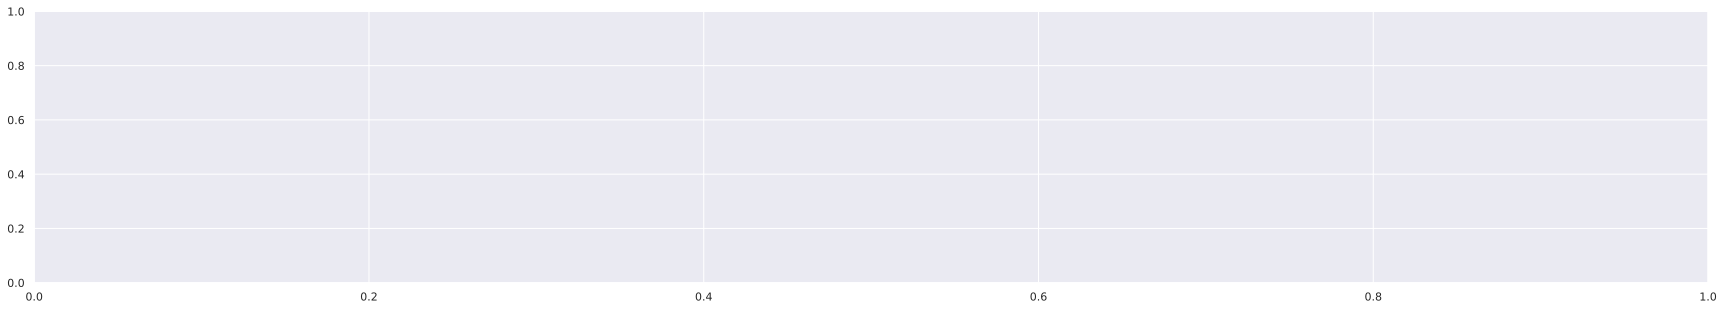

In [64]:
#plot
plt.figure(figsize=(30,5))
index = np.arange(len(labels))
plt.bar(index, no_of_recordings)
plt.xlabel('Commands', fontsize=12)
plt.ylabel('No of recordings', fontsize=12)
plt.xticks(index, labels, fontsize=15, rotation=60)
plt.title('No. of recordings for each command')
plt.show()

In [65]:
# #find count of each label and plot bar graph
# no_of_recordings=[]
# for label in labels:
#     #f = os.listdir(train_audio_path + label)
#     waves = [f for f in os.listdir(train_audio_path + label) if f.endswith('.wav')]
#     no_of_recordings.append(len(waves))
    
# #plot
# plt.figure(figsize=(30,5))
# index = np.arange(len(labels))
# plt.bar(index, no_of_recordings)
# plt.xlabel('Commands', fontsize=12)
# plt.ylabel('No of recordings', fontsize=12)
# plt.xticks(index, labels, fontsize=15, rotation=60)
# plt.title('No. of recordings for each command')
# plt.show()

**Duration of recordings**

What’s next? A look at the distribution of the duration of recordings:

(array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <a list of 10 Patch objects>)

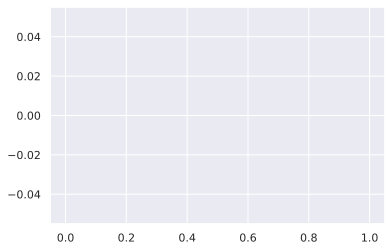

In [66]:
duration_of_recordings=[]
for label in labels:
  for files in os.listdir(train_audio_path):
      sourceFile = os.path.join(train_audio_path + label, files)
      if os.path.isfile(sourceFile) and sourceFile.endswith('.wav'):
        waves = [files]
        no_of_recordings.append(len(waves))
    #waves = [f for f in os.listdir(train_audio_path + label) if f.endswith('.wav')]
        for wav in waves:
            sample_rate, samples = wavfile.read(train_audio_path + '/' + label + '/' + wav)
            duration_of_recordings.append(float(len(samples)/sample_rate))
    
plt.hist(np.array(duration_of_recordings))

**Preprocessing the audio waves**

In the data exploration part earlier, we have seen that the duration of a few recordings is less than 1 second and the sampling rate is too high. So, let us read the audio waves and use the below-preprocessing steps to deal with this.

Here are the two steps we’ll follow:

Resampling
Removing shorter commands of less than 1 second
Let us define these preprocessing steps in the below code snippet:

In [67]:
train_audio_path = '/content/audio'

all_wave = []
all_label = []
for label in labels:
    print(label)
    #waves = [f for f in os.listdir(train_audio_path + '/'+ label) if f.endswith('.wav')]
    for files in os.listdir(train_audio_path):
      sourceFile = os.path.join(train_audio_path + label, files)
      if os.path.isfile(sourceFile) and sourceFile.endswith('.wav'):
        waves = [files]
        no_of_recordings.append(len(waves))
        for wav in waves:
           samples, sample_rate = librosa.load(train_audio_path + '/' + label + '/' + wav, sr = 16000)
           samples = librosa.resample(samples, sample_rate, 8000)
           if(len(samples)== 8000) : 
               all_wave.append(samples)
               all_label.append(label)

WhatsApp-Ptt-2022-01-26-at-1.07.43-AM.wav
WhatsApp-Ptt-2022-01-18-at-11.11.12-PM.wav
